# Walkthrough: EV charging station analytics (Station 1)

This notebook shows the main steps of the pipeline on one station. All logic lives in `src/evcs/`; to regenerate every table and figure for all stations, run `python scripts/run_analysis.py`.

Requires the raw meter file `data/raw/IHM10050174.csv` (not public, see `data/README.md`).

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.simplefilter('ignore')

import pandas as pd
from IPython.display import Image
from evcs import analysis, config, forecast, io, tariff

## 1. Load the meter export and build 15-minute interval energy

The meter logs a *cumulative* import register (OBIS `1-0:1.8.0`). Energy per interval is the difference between consecutive readings. The export register (`1-0:2.8.0`) is excluded.

In [2]:
raw = io.read_meter_export(config.raw_file(1))
energy = io.interval_energy(raw)
print(f'{len(energy)} readings, {energy.index.min()} to {energy.index.max()}')
energy.head()

2903 readings, 2023-03-01 00:11:19+05:30 to 2023-03-31 15:12:07+05:30


,cumulative_kwh,energy_kwh
Reading time,,
2023-03-01 00:11:19+05:30,1884.03,0.00
2023-03-01 00:26:15+05:30,1884.48,0.45
2023-03-01 00:41:11+05:30,1884.93,0.45
2023-03-01 00:56:18+05:30,1885.39,0.46
2023-03-01 01:11:14+05:30,1885.84,0.45


### Cross-check against the meter's own 30-minute block-load profile

In [3]:
print('Interval method :', round(energy['energy_kwh'].sum(), 2), 'kWh')
print('Block-load total:', round(io.block_load_energy(raw).sum(), 2), 'kWh')

Interval method : 328.7 kWh
Block-load total: 328.99 kWh


## 2. Daily energy and summary statistics

In [4]:
daily = analysis.daily_energy(energy)
analysis.summary_stats(daily)

{'total_kwh': 328.7,
 'mean_daily_kwh': 10.6,
 'median_daily_kwh': 11.85,
 'std_daily_kwh': 6.51,
 'min_daily_kwh': 0.0,
 'max_daily_kwh': 23.31}

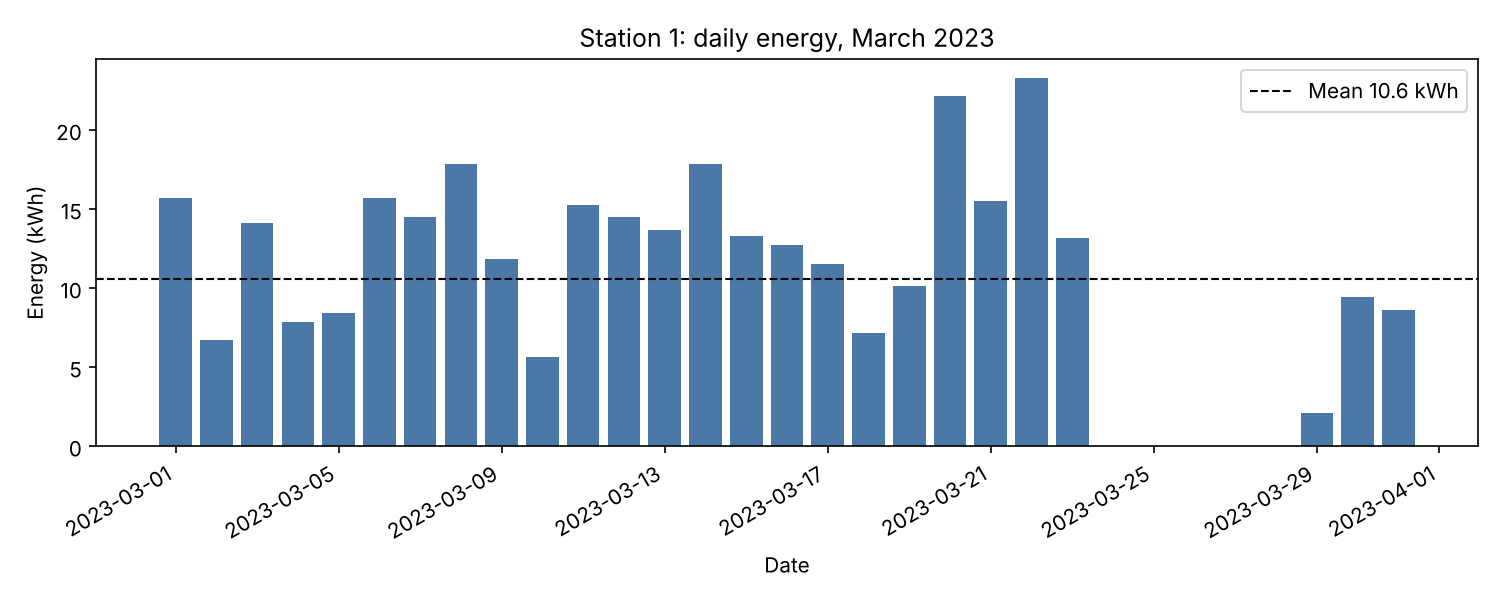

In [5]:
Image('../results/figures/station_1_daily.png')

Station 1 drew no energy from 24 to 28 March, which looks like an outage or the charger being taken out of service. Keep this in mind for any averages.

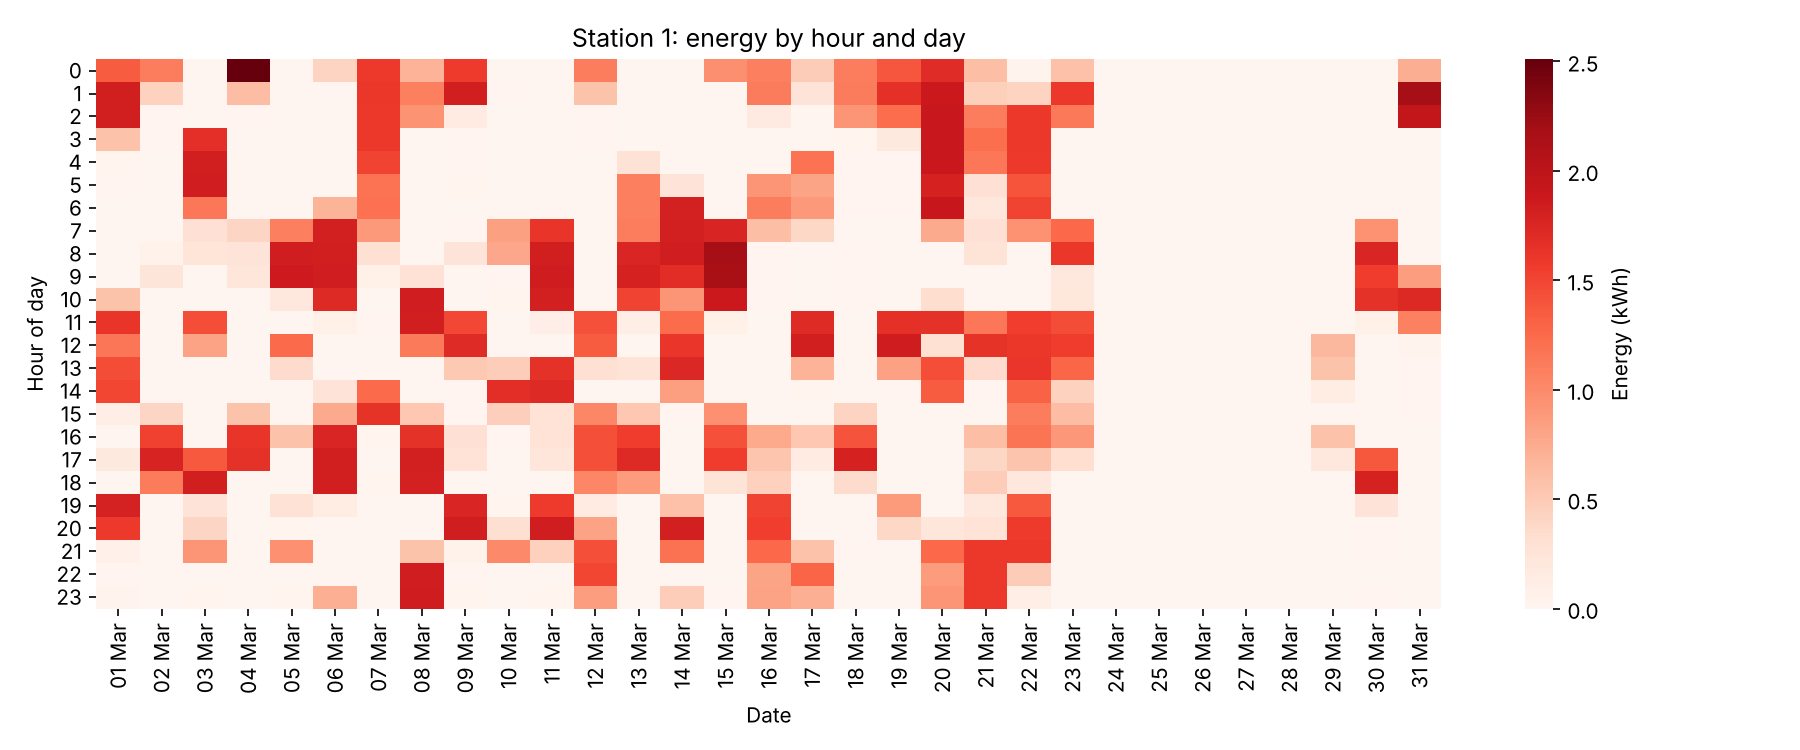

In [6]:
Image('../results/figures/station_1_heatmap.png')

## 3. Time-of-day tariff cost

In [7]:
priced = tariff.apply_tariff(energy, tariff.TARIFF_SCENARIOS['utility_tod'])
tariff.band_summary(priced)

,energy_kwh,cost_inr,energy_share_pct
band,,,
off-peak,99.86,599.16,30.38
peak,62.86,502.88,19.12
mid-peak,121.17,848.19,36.86
high-peak,44.81,358.48,13.63
total,328.70,2308.71,100.00


## 4. Weekday vs weekend, holidays

In [8]:
analysis.weekday_vs_weekend(daily)

{'weekday_days': 23,
 'weekend_days': 8,
 'weekday_mean_kwh': 11.54,
 'weekend_mean_kwh': 7.92,
 't_stat': 1.479,
 'p_value': 0.161,
 'significant': False}

In [9]:
analysis.holiday_vs_other(daily)

{'holiday_days': 2, 'holiday_mean_kwh': 20.58, 'other_mean_kwh': 9.92}

With only 8 weekend days and 2 holidays in one month, these comparisons are descriptive. They are not strong evidence either way.

## 5. Charging sessions (approximate)

In [10]:
sessions = analysis.charging_sessions(energy)
print(len(sessions), 'sessions')
sessions['energy_kwh'].describe().round(2)

98 sessions


count    98.00
mean      3.34
std       2.81
min       0.25
25%       0.73
50%       3.08
75%       4.86
max      13.75
Name: energy_kwh, dtype: float64

## 6. Hour-ahead forecasting vs simple baselines

In [11]:
metrics, preds = forecast.evaluate(forecast.hourly_series(energy))
metrics

,MAE,RMSE,R2
model,,,
persistence,0.1272,0.3731,0.2756
seasonal_naive,0.1646,0.4713,-0.1560
xgboost,0.3126,0.3873,0.2195


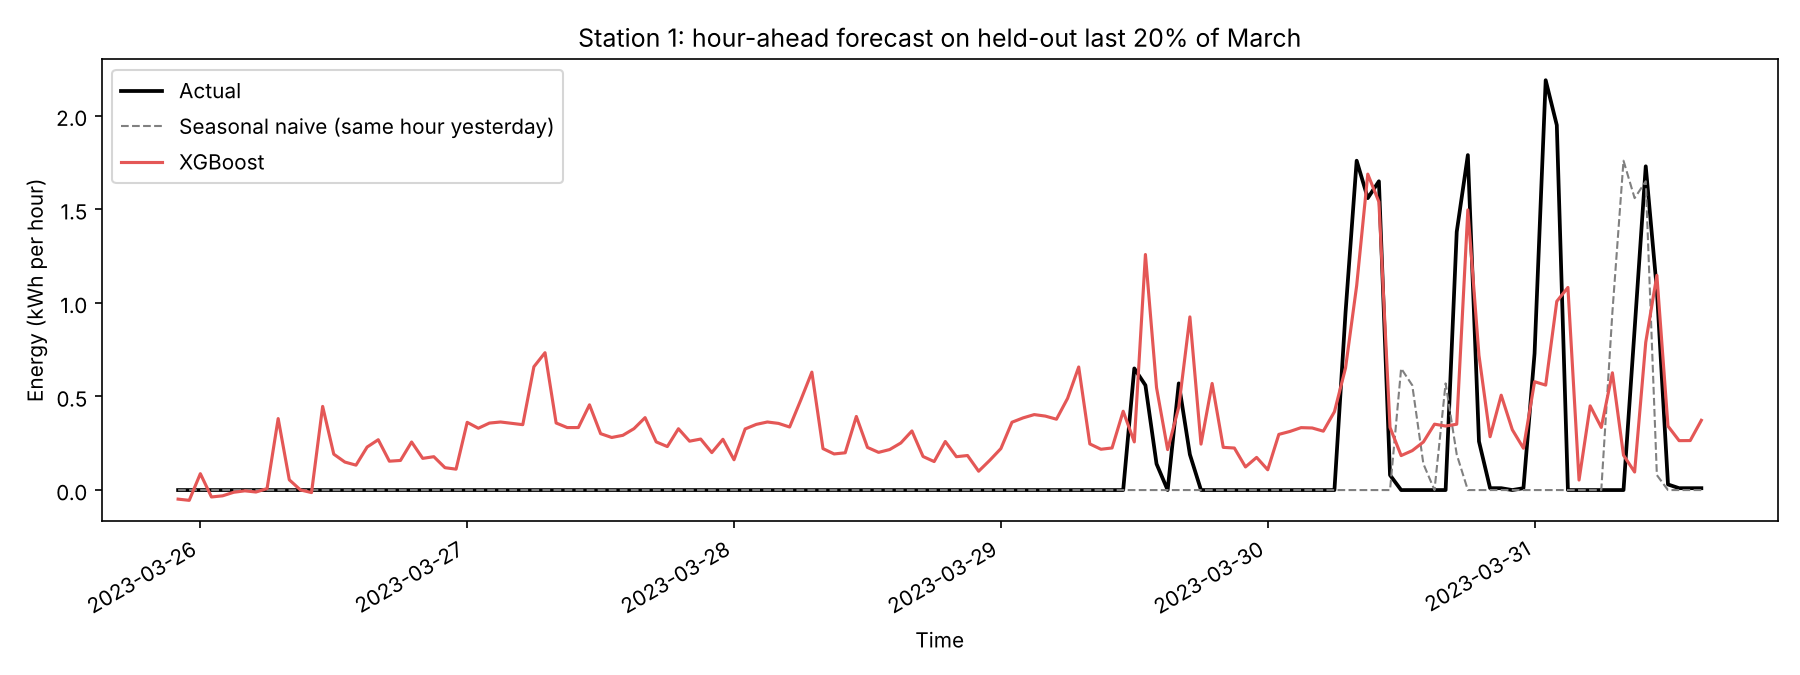

In [12]:
Image('../results/figures/station_1_forecast.png')

XGBoost does **not** beat the persistence baseline on this data. One month of hourly data (about 740 points), with an outage inside the test period, is too little to learn a reliable model. A credible forecasting claim needs several months of data and evaluation over several test windows.